In [14]:
import numpy as np
import matplotlib.pyplot as plt
from pandas import read_csv
import math
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

# convert an array of values into a dataset matrix
def create_dataset(dataset, look_back=1):
    dataX, dataY = [], []
    for i in range(len(dataset)-look_back-1):
        a = dataset[i:(i+look_back), 0]
        dataX.append(a)
        dataY.append(dataset[i + look_back, 0])
    return np.array(dataX), np.array(dataY)

# fix random seed for reproducibility
tf.random.set_seed(7)

# load the dataset
dataframe = read_csv('../preprocess/parking_time_series_with_features.csv', usecols=[1], engine='python')
dataset = dataframe.values
dataset = dataset.astype('float32')


In [15]:
# Normalize the dataset
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

# Determine sizes for the split
train_start = 0
train_end = int(len(dataset) * 0.4)
test_start = int(len(dataset) * 0.4)
test_end = int(len(dataset) * 0.6)

# Include the last 40% in the training set
train_end_extended = int(len(dataset) * 0.8)

# Split into train and test sets
train = dataset[train_start:train_end_extended, :]
test = dataset[test_start:test_end, :]

# reshape into X=t and Y=t+1
look_back = 1
trainX, trainY = create_dataset(train, look_back)
testX, testY = create_dataset(test, look_back)

# Reshape input to be [samples, time steps, features]
trainX = np.reshape(trainX, (trainX.shape[0], 1, trainX.shape[1]))
testX = np.reshape(testX, (testX.shape[0], 1, testX.shape[1]))

# create and fit the LSTM network
model = Sequential()
model.add(LSTM(4, input_shape=(1, look_back)))
model.add(Dense(1))
model.compile(loss='mean_squared_error', optimizer='adam')
model.fit(trainX, trainY, epochs=10, batch_size=1, verbose=2)


Epoch 1/10


c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


110582/110582 - 41s - 368us/step - loss: 5.5184e-04
Epoch 2/10
110582/110582 - 39s - 352us/step - loss: 4.3814e-05
Epoch 3/10
110582/110582 - 39s - 351us/step - loss: 4.3238e-05
Epoch 4/10
110582/110582 - 39s - 357us/step - loss: 4.2858e-05
Epoch 5/10
110582/110582 - 44s - 394us/step - loss: 4.2543e-05
Epoch 6/10
110582/110582 - 44s - 400us/step - loss: 4.2255e-05
Epoch 7/10
110582/110582 - 44s - 394us/step - loss: 4.2015e-05
Epoch 8/10
110582/110582 - 42s - 376us/step - loss: 4.1839e-05
Epoch 9/10
110582/110582 - 38s - 345us/step - loss: 4.1683e-05
Epoch 10/10
110582/110582 - 40s - 358us/step - loss: 4.1545e-05


3456/3456 ━━━━━━━━━━━━━━━━━━━━ 1s 348us/step
864/864 ━━━━━━━━━━━━━━━━━━━━ 0s 335us/step
Train Score: 7.13 RMSE
Test Score: 7.05 RMSE


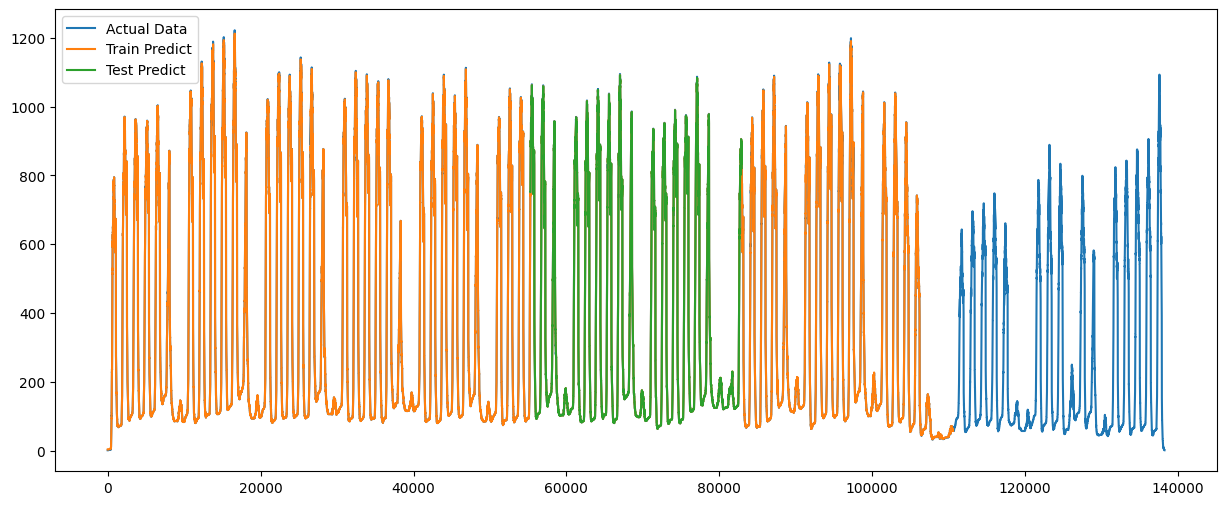

In [16]:

# Predictions
trainPredict = model.predict(trainX)
testPredict = model.predict(testX)

# Invert predictions
trainPredict = scaler.inverse_transform(trainPredict)
trainY = scaler.inverse_transform(trainY.reshape(-1, 1))  # Reshape trainY to match trainPredict shape
testPredict = scaler.inverse_transform(testPredict)
testY = scaler.inverse_transform(testY.reshape(-1, 1))  # Reshape testY to match testPredict shape

# Calculate RMSE
trainScore = np.sqrt(mean_squared_error(trainY, trainPredict))
print('Train Score: %.2f RMSE' % (trainScore))
testScore = np.sqrt(mean_squared_error(testY, testPredict))
print('Test Score: %.2f RMSE' % (testScore))

# Shift predictions for plotting
trainPredictPlot = np.empty_like(dataset)
trainPredictPlot[:, :] = np.nan
trainPredictPlot[look_back:len(trainPredict)+look_back, :] = trainPredict

testPredictPlot = np.empty_like(dataset)
testPredictPlot[:, :] = np.nan
testPredictPlot[train_end+look_back+1:train_end+look_back+1+len(testPredict), :] = testPredict

# Plotting
plt.figure(figsize=(15, 6))
plt.plot(scaler.inverse_transform(dataset), label='Actual Data')
plt.plot(trainPredictPlot, label='Train Predict')
plt.plot(testPredictPlot, label='Test Predict')
plt.legend()
plt.show()